# ABC Optimizer — Usage Example

This notebook shows how to solve a Resource-Constrained Project Scheduling Problem (RCPSP) instance using the Artificial Bee Colony algorithm.

## 1. Load a benchmark dataset

In [1]:
from swarm import ABC, RCPSPOperators, load_dataset, Schedule, topological_sort

# Load all 480 instances of the j30 dataset (30 jobs each)
# Best-known solutions are attached automatically
problems = load_dataset("j30")

problem = problems[0]
print(f"Problem: {problem.name}")
print(f"Jobs: {len(problem.jobs)}")
print(f"Resources: {len(problem.resources.resources_list)}")
print(f"Best known makespan: {problem.best_known}")

Problem: j301_1
Jobs: 32
Resources: 4
Best known makespan: 43


## 2. Run the ABC optimizer

The optimizer uses an ask/tell interface: `ask()` returns candidate schedules, we evaluate them (their makespan) and report the values back with `tell()`. The loop is ours, so we also record the convergence curve here.

In [2]:
optimizer = ABC(
    RCPSPOperators(problem, heuristics_rate=0.0, sampling_rate=15),
    population_size=10,
    limit=100,
    seed=42,
)

evaluations, makespans = [], []
while optimizer.n_evaluations < 25000 and optimizer.best_fitness > problem.best_known:
    schedules = optimizer.ask()
    optimizer.tell([s.get_makespan() for s in schedules])
    evaluations.append(optimizer.n_evaluations)
    makespans.append(optimizer.best_fitness)

print(f"Best makespan: {optimizer.best.get_makespan()}  (best known: {problem.best_known})")
print(f"Evaluations used: {optimizer.n_evaluations}")

Best makespan: 45  (best known: 43)
Evaluations used: 25000


## 3. Convergence plot

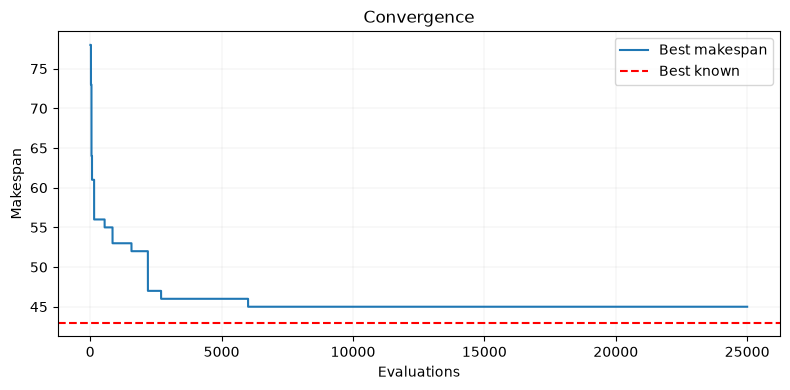

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(evaluations, makespans, label="Best makespan")
plt.axhline(y=problem.best_known, color="r", linestyle="--", label="Best known")
plt.xlabel("Evaluations")
plt.ylabel("Makespan")
plt.title("Convergence")
plt.legend()
plt.grid(True, linewidth=0.25, alpha=0.5)
plt.tight_layout()
plt.show()

## 4. Visualize the schedule

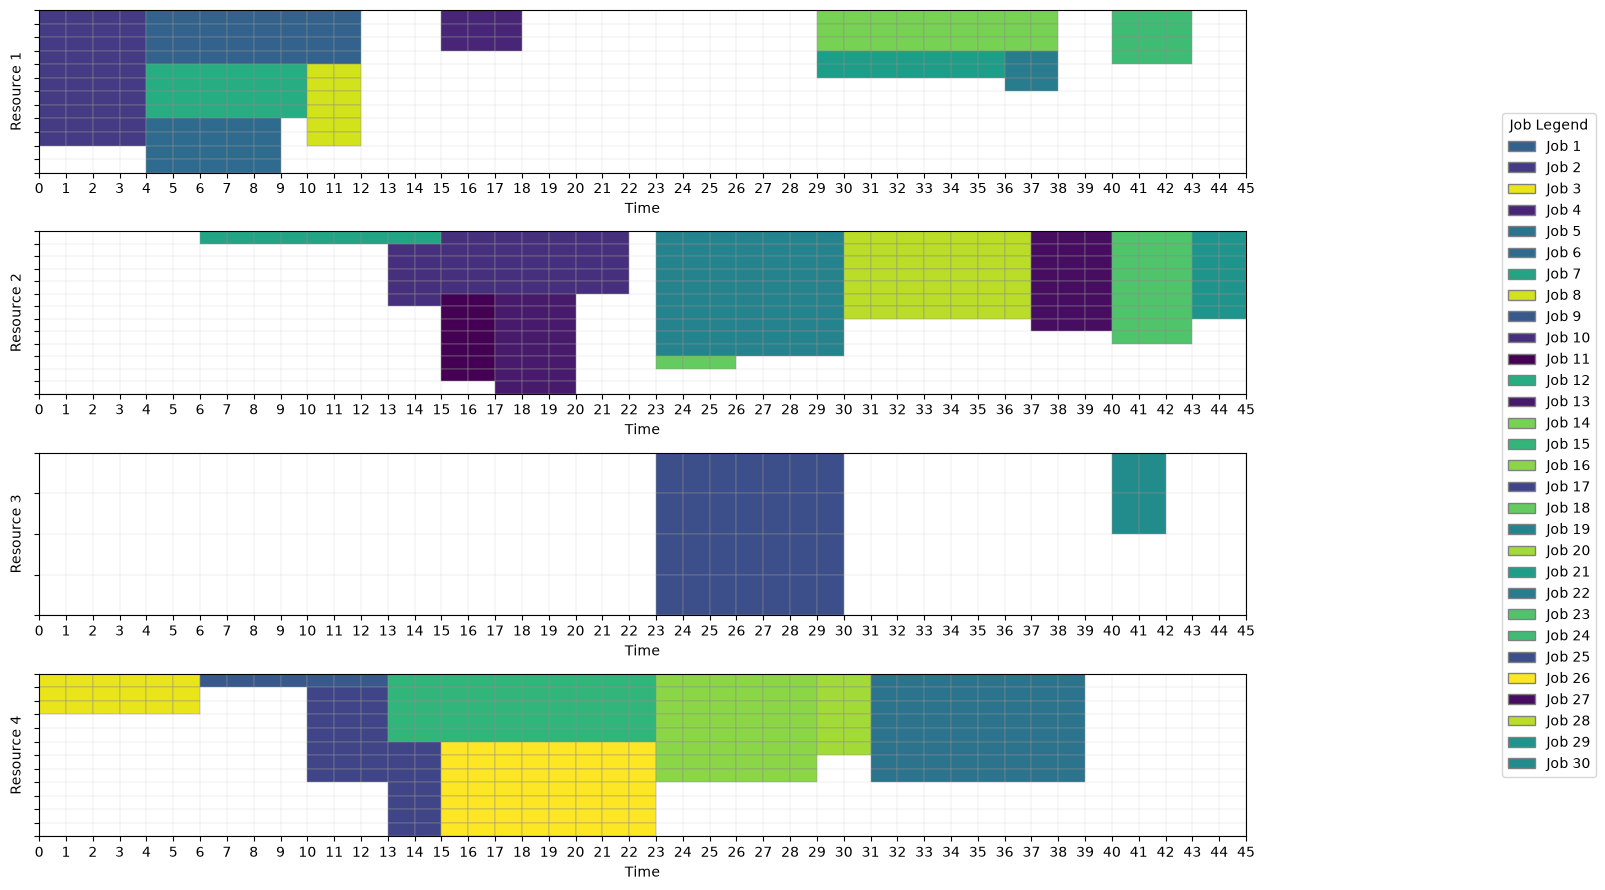

In [4]:
optimizer.best.plot()

## 5. Compare scheduling heuristics

Build a single schedule using each priority rule (no optimization) and compare makespans.

In [5]:
for metric in ["ldf", "sdf", "mrf", "lrf", "random"]:
    jobs = topological_sort(problem.jobs, metric=metric)
    schedule = Schedule(psmodel=problem, jobs=jobs)
    print(f"{metric:>6s}: makespan = {schedule.get_makespan()}")

   ldf: makespan = 98
   sdf: makespan = 93
   mrf: makespan = 91
   lrf: makespan = 78
random: makespan = 92
